In [ ]:
import zipfile
import os

zip_path = '/content/archive (1).zip'
extract_path = '/content/emotion_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:")
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

Extracted files:
/content/emotion_dataset/validation.csv
/content/emotion_dataset/training.csv
/content/emotion_dataset/test.csv


Current files in /content: ['.config', 'emotion_dataset', 'archive (1).zip', 'sample_data']
Train size: 16000, Val size: 2000, Test size: 2000
Label distribution in training data:
 label
1    5362
0    4666
3    2159
4    1937
2    1304
5     572
Name: count, dtype: int64

--- Training Baseline Model (TF-IDF + Logistic Regression) ---
Baseline Test Accuracy: 0.8685

--- Preparing RoBERTa Dataset and Model ---
Using device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



--- Epoch 1/3 ---
Train Loss: 0.5932 | Val Loss: 0.2333

--- Epoch 2/3 ---
Train Loss: 0.1947 | Val Loss: 0.1686

--- Epoch 3/3 ---
Train Loss: 0.1282 | Val Loss: 0.1415

RoBERTa Test Accuracy: 0.9290

Classification Report for RoBERTa:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       581
           1       0.97      0.93      0.95       695
           2       0.81      0.91      0.86       159
           3       0.96      0.90      0.93       275
           4       0.87      0.91      0.89       224
           5       0.72      0.80      0.76        66

    accuracy                           0.93      2000
   macro avg       0.88      0.90      0.89      2000
weighted avg       0.93      0.93      0.93      2000



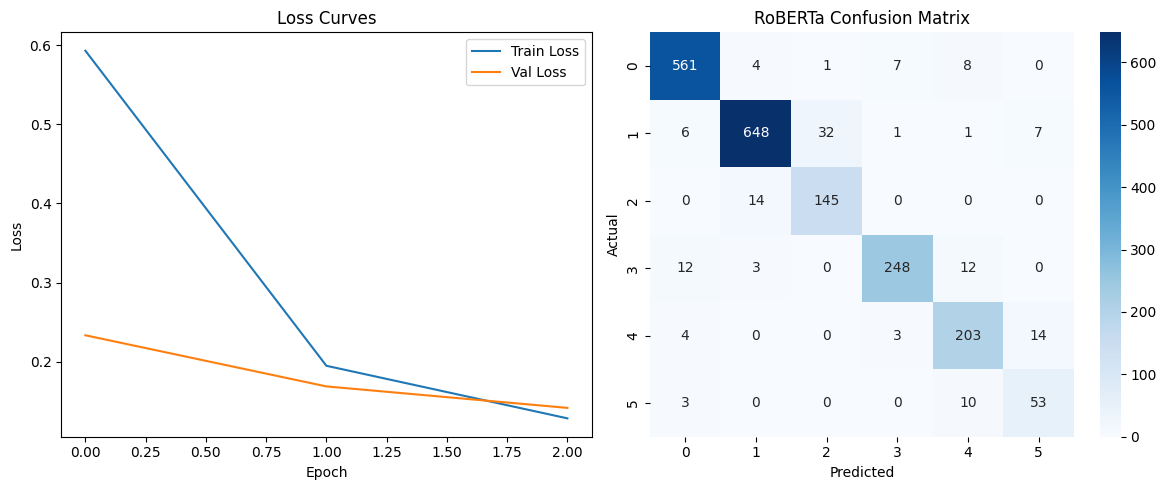


--- Final Summary Comparison ---
TF-IDF Baseline Accuracy: 0.8685
RoBERTa Model Accuracy:   0.9290


In [ ]:
import zipfile
import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import RobertaTokenizer, RobertaModel, get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract Dataset with verification
print("Current files in /content:", os.listdir('/content'))
zip_path = '/content/archive (1).zip'
extract_path = '/content/emotion_dataset'

if not os.path.exists(extract_path):
    if not os.path.exists(zip_path):
        # Attempt to find the file if spelling or spaces differ
        for file in os.listdir('/content'):
            if 'archive' in file and file.endswith('.zip'):
                zip_path = os.path.join('/content', file)
                break

    print(f"Extracting dataset from: {zip_path}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extraction complete.")

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 2. Load Data
train_df = pd.read_csv('/content/emotion_dataset/training.csv')
val_df = pd.read_csv('/content/emotion_dataset/validation.csv')
test_df = pd.read_csv('/content/emotion_dataset/test.csv')

print(f"Train size: {len(train_df)}, Val size: {len(val_df)}, Test size: {len(test_df)}")
print("Label distribution in training data:\n", train_df['label'].value_counts())

# --- BASELINE MODEL (TF-IDF + Logistic Regression) ---
print("\n--- Training Baseline Model (TF-IDF + Logistic Regression) ---")
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(train_df['text'])
X_test_tfidf = vectorizer.transform(test_df['text'])
y_train = train_df['label']
y_test = test_df['label']

baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train_tfidf, y_train)
baseline_preds = baseline_model.predict(X_test_tfidf)
baseline_acc = accuracy_score(y_test, baseline_preds)
print(f"Baseline Test Accuracy: {baseline_acc:.4f}")

# --- ROBERTA MODEL ---
print("\n--- Preparing RoBERTa Dataset and Model ---")
PRE_TRAINED_MODEL_NAME = 'roberta-base'
tokener_name = PRE_TRAINED_MODEL_NAME
tokenizer = RobertaTokenizer.from_pretrained(PRE_TRAINED_MODEL_NAME)

class EmotionDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = str(self.texts[item])
        label = self.labels[item]
        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='pt',
        )
        return {
            'text': text,
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'label': torch.tensor(label, dtype=torch.long)
        }

MAX_LEN = 128
BATCH_SIZE = 32

train_dataset = EmotionDataset(train_df['text'].values, train_df['label'].values, tokenizer, MAX_LEN)
val_dataset = EmotionDataset(val_df['text'].values, val_df['label'].values, tokenizer, MAX_LEN)
test_dataset = EmotionDataset(test_df['text'].values, test_df['label'].values, tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

class EmotionClassifier(nn.Module):
    def __init__(self, n_classes):
        super(EmotionClassifier, self).__init__()
        self.roberta = RobertaModel.from_pretrained(PRE_TRAINED_MODEL_NAME)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.roberta.config.hidden_size, n_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.roberta(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.pooler_output
        output = self.drop(pooled_output)
        return self.out(output)

num_classes = len(train_df['label'].unique())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = EmotionClassifier(num_classes)
model = model.to(device)

EPOCHS = 3
optimizer = AdamW(model.parameters(), lr=2e-5)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)
loss_fn = nn.CrossEntropyLoss().to(device)

# Training Loop
train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    print(f"\n--- Epoch {epoch + 1}/{EPOCHS} ---")
    model.train()
    total_train_loss = 0
    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = loss_fn(outputs, labels)
        total_train_loss += loss.item()

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            loss = loss_fn(outputs, labels)
            total_val_loss += loss.item()

    avg_val_loss = total_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

# Evaluation
model.eval()
predictions = []
real_values = []
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        _, preds = torch.max(outputs, dim=1)
        predictions.extend(preds.cpu().tolist())
        real_values.extend(labels.cpu().tolist())

roberta_acc = accuracy_score(real_values, predictions)
print(f"\nRoBERTa Test Accuracy: {roberta_acc:.4f}")
print("\nClassification Report for RoBERTa:")
print(classification_report(real_values, predictions))

# Visualization
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
cm = confusion_matrix(real_values, predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('RoBERTa Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Performance Comparison
print(f"\n--- Final Summary Comparison ---")
print(f"TF-IDF Baseline Accuracy: {baseline_acc:.4f}")
print(f"RoBERTa Model Accuracy:   {roberta_acc:.4f}")